<a href="https://colab.research.google.com/github/archanashinde001/multimodal-stance-models/blob/main/multimodal_model_comparison_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparing open-weight models for stance in multimodal social-media posts

**Below are some comparisons of the modality done in this notebook:**

| |Comparison | Models | |
|---|---|---|---|
|  | Text models | RoBERTa-base, GPT-Neo-125M, TinyLlama-1.1B, CLIP Text ||
|  | Meme models | ResNet18, ViT-B/16, CLIP meme | |
|  | CLIP: text only, meme only, text + meme | CLIP Text, CLIP meme, CLIP Text + meme | |
|  | SmolVLM: input type and model size | 256M and 500M, each with text only, meme only, text + meme | |

**Run:** upload `post-text.xlsx`, `memes.xlsx` and `memes.zip` to `/content/study`, choose a T4 GPU, then *Runtime > Run all*.


In [1]:
# transformers: loads the pretrained models; accelerate: faster model loading; openpyxl: reads Excel files
!pip -q install transformers accelerate openpyxl

In [2]:
# ================= Settings =================
from pathlib import Path

BASE       = Path("/content/study")      # create a folder study in content and then add the three input files
POST_TEXT_XLSX  = BASE / "post-text.xlsx"
MEMES_XLSX = BASE / "memes.xlsx"
MEMES_ZIP  = BASE / "memes.zip"
MEMES_DIR  = BASE / "memes"              # the zip is extracted here
OUT        = BASE / "results"            # tables and figures are written here (overwritten each run)

# Column names in the dataset
ID_COL, POST_TEXT_COL = "ID", "Post-Text"
POST_TEXT_LABEL_COL = "Post-text_human_coding"
MEMES_LABEL_COL   = "Meme_human_coding"

def meme_stem(post_id):
    """Meme file name (without extension) for a post ID. Edit if your files are named differently."""
    return str(post_id)

CLASSES = ["Anti-Mandate", "Pro-Mandate", "Neutral", "Other"]

SEED      = 42     # one seed for everything, so every run gives the same splits and results
N_FOLDS   = 5      # cross-validation folds (reduced automatically if the rarest class is smaller)
N_REPEATS = 5      # cross-validation is repeated with 5 different shuffles
N_BOOT    = 1000   # bootstrap resamples for the 95% intervals
C_VALUE   = 1.0    # logistic regression strength, fixed for every model
MAX_TEXT_TOKENS = 128   # RoBERTa / GPT-Neo / TinyLlama read at most this many tokens per post

MODEL_IDS = {
    "RoBERTa-base":   "roberta-base",
    "GPT-Neo-125M":   "EleutherAI/gpt-neo-125M",
    "TinyLlama-1.1B": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    "CLIP":           "openai/clip-vit-base-patch16",
    "SmolVLM-256M":   "HuggingFaceTB/SmolVLM-256M-Instruct",
    "SmolVLM-500M":   "HuggingFaceTB/SmolVLM-500M-Instruct",
}   # ResNet18 and ViT-B/16 come from torchvision (ImageNet weights)

In [3]:
# ================= Setup =================
import json, gc, time, zipfile, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "(a T4 GPU is recommended: Runtime > Change runtime type)")

OUT.mkdir(parents=True, exist_ok=True)
(OUT / "supplement").mkdir(exist_ok=True)

# Software versions, saved next to the results so the run can be reproduced
from importlib.metadata import version, PackageNotFoundError
def _ver(pkg):
    try: return f"{pkg}=={version(pkg)}"
    except PackageNotFoundError: return f"{pkg} (not installed)"
versions = [_ver(p) for p in ["torch", "torchvision", "transformers", "scikit-learn", "pandas", "numpy", "Pillow"]]
(OUT / "versions.txt").write_text("\n".join(versions) + f"\ndevice={DEVICE}\nseed={SEED}\n")
print("\n".join(versions))

device: cuda (a T4 GPU is recommended: Runtime > Change runtime type)
torch==2.11.0+cu130
torchvision==0.26.0+cu130
transformers==5.21.0
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
Pillow==11.3.0


In [4]:
# ================= Load the data =================
if not MEMES_DIR.exists():
    with zipfile.ZipFile(MEMES_ZIP) as z:
        z.extractall(MEMES_DIR)

txt = pd.read_excel(POST_TEXT_XLSX)
img = pd.read_excel(MEMES_XLSX)
# stops with an error if an ID appears twice
df = txt[[ID_COL, POST_TEXT_COL, POST_TEXT_LABEL_COL]].merge(
    img[[ID_COL, MEMES_LABEL_COL]], on=ID_COL, how="inner", validate="one_to_one")
print(len(txt), "post-text rows |", len(img), "memes rows |", len(df), "posts after matching by ID")

# No text cleaning: hashtags, emojis and capitals can carry stance.
df["Post-Text"] = df[POST_TEXT_COL].astype(str).str.strip()
for c in (POST_TEXT_LABEL_COL, MEMES_LABEL_COL):
    df[c] = df[c].astype(str).str.strip()
unknown = (set(df[POST_TEXT_LABEL_COL]) | set(df[MEMES_LABEL_COL])) - set(CLASSES)
assert not unknown, f"Labels not in CLASSES (typo or extra spaces?): {unknown}"

files = {p.stem: p for p in MEMES_DIR.rglob("*")
         if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".gif"}}
df["path"] = [files.get(meme_stem(i)) for i in df[ID_COL]]
n_missing = int(df["path"].isna().sum())
assert n_missing == 0, f"{n_missing} posts have no memes file. Edit meme_stem(). Example file names: {list(files)[:3]}"

LABEL_COLS = {"Post-Text": POST_TEXT_LABEL_COL, "Memes": MEMES_LABEL_COL}
Y = {lab: df[col].to_numpy(dtype=object) for lab, col in LABEL_COLS.items()}
texts, paths = df["Post-Text"].tolist(), df["path"].tolist()

200 post-text rows | 200 memes rows | 200 posts after matching by ID


In [5]:
# ================= Look at the data =================
for lab, col in LABEL_COLS.items():
    print(f"\n{lab.upper()} LABEL counts:")
    counts = df[col].value_counts().reindex(CLASSES).fillna(0).astype(int)
    for cls, val in counts.items():
        print(f"{cls:<15} {val}")

# Posts with identical text (but different memes) share a group id, so that cross-validation
# never puts one copy in training and the other in testing.
groups = pd.factorize(df["Post-Text"].str.lower().str.strip())[0]
print(f"\n{len(df)} posts, {len(set(groups))} distinct post-texts")


POST-TEXT LABEL counts:
Anti-Mandate    30
Pro-Mandate     45
Neutral         34
Other           91

MEMES LABEL counts:
Anti-Mandate    40
Pro-Mandate     126
Neutral         26
Other           8

200 posts, 195 distinct post-texts


In [6]:
# ================= Cross-validation splits =================
# Made once per label at the start of the run and used by EVERY model.
# Stratified = similar class proportions in every fold; grouped = duplicate post-texts stay together.
# The fixed seed gives identical splits on every run. They are saved to a file as a record only.
def make_splits(y, groups):
    smallest = int(pd.Series(y).value_counts().min())
    n_splits = max(2, min(N_FOLDS, smallest))
    if n_splits < N_FOLDS:
        print(f"  note: rarest class has {smallest} posts, using {n_splits} folds")
    splits = []
    for r in range(N_REPEATS):
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED + r)
        for tr, te in cv.split(np.zeros(len(y)), y, groups):
            assert not set(groups[tr]) & set(groups[te]), "duplicate post-text in both train and test"
            splits.append((r, tr, te))
    return splits

SPLITS = {lab: make_splits(Y[lab], groups) for lab in LABEL_COLS}
for lab, s in SPLITS.items():
    json.dump([[r, tr.tolist(), te.tolist()] for r, tr, te in s], open(OUT / f"splits_{lab}_label.json", "w"))
print("splits ready:", {lab: len(s) for lab, s in SPLITS.items()}, "train/test splits per label")

# Posts per class in training and testing (over the 25 splits of each label)
rows = []
for lab, s in SPLITS.items():
    y = Y[lab]
    for c in CLASSES + ["All classes"]:
        is_c = np.ones(len(y), bool) if c == "All classes" else (y == c)
        n_tr = [int(is_c[tr].sum()) for _, tr, _ in s]
        n_te = [int(is_c[te].sum()) for _, _, te in s]
        rows.append({"Label": lab, "Class": c, "Total": int(is_c.sum()),
                     "Train per fold (mean)": round(np.mean(n_tr), 1), "Train (min-max)": f"{min(n_tr)}-{max(n_tr)}",
                     "Test per fold (mean)": round(np.mean(n_te), 1), "Test (min-max)": f"{min(n_te)}-{max(n_te)}"})
SPLIT_TABLE = pd.DataFrame(rows)
SPLIT_TABLE.to_csv(OUT / "table_data_train_test_per_class.csv", index=False)
print("\n=== Posts per class in training and testing ===")
print(SPLIT_TABLE.to_string(index=False))

splits ready: {'Post-Text': 25, 'Memes': 25} train/test splits per label

=== Posts per class in training and testing ===
    Label        Class  Total  Train per fold (mean) Train (min-max)  Test per fold (mean) Test (min-max)
Post-Text Anti-Mandate     30                   24.0           21-29                   6.0            1-9
Post-Text  Pro-Mandate     45                   36.0           32-41                   9.0           4-13
Post-Text      Neutral     34                   27.2           24-31                   6.8           3-10
Post-Text        Other     91                   72.8           68-78                  18.2          13-23
Post-Text  All classes    200                  160.0         156-163                  40.0          37-44
    Memes Anti-Mandate     40                   32.0           28-37                   8.0           3-12
    Memes  Pro-Mandate    126                  100.8          95-107                  25.2          19-31
    Memes      Neutral     26 

In [7]:
# ================= Feature Extraction =================
def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def load_rgb(path):
    return Image.open(path).convert("RGB")

def embed_text(model_id, texts, batch_size=16):
    """RoBERTa / GPT-Neo / TinyLlama: mean of the last hidden layer over the post's tokens."""
    from transformers import AutoTokenizer, AutoModel
    dtype = torch.float16 if DEVICE == "cuda" else torch.float32
    tok = AutoTokenizer.from_pretrained(model_id)
    if tok.pad_token is None:                       # GPT-style models have no padding token
        tok.pad_token = tok.eos_token
    n_cut = sum(len(ids) > MAX_TEXT_TOKENS for ids in tok(texts)["input_ids"])
    model = AutoModel.from_pretrained(model_id, torch_dtype=dtype).to(DEVICE).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = tok(texts[i:i + batch_size], padding=True, truncation=True,
                      max_length=MAX_TEXT_TOKENS, return_tensors="pt").to(DEVICE)
            h = model(**enc).last_hidden_state                       # (batch, tokens, dim)
            m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)      # ignore padding
            out.append(((h * m).sum(1) / m.sum(1)).float().cpu().numpy())
    del model; free_gpu()
    return np.vstack(out)

def embed_memes(arch, paths, batch_size=32):
    """ResNet18 / ViT-B/16 (torchvision, ImageNet weights), classification layer removed."""
    from torchvision import models
    if arch == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT
        model = models.resnet18(weights=weights); model.fc = torch.nn.Identity()
    else:
        weights = models.ViT_B_16_Weights.DEFAULT
        model = models.vit_b_16(weights=weights); model.heads = torch.nn.Identity()
    prep = weights.transforms()                    # the resize/normalise recipe the model was trained with
    model = model.to(DEVICE).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), batch_size):
            batch = torch.stack([prep(load_rgb(p)) for p in paths[i:i + batch_size]]).to(DEVICE)
            out.append(model(batch).float().cpu().numpy())
    del model; free_gpu()
    return np.vstack(out)

def embed_clip(model_id, texts, paths, batch_size=32):
    """CLIP: text vectors and image vectors in the same space, each scaled to length 1."""
    from transformers import CLIPModel, CLIPProcessor
    proc = CLIPProcessor.from_pretrained(model_id)
    model = CLIPModel.from_pretrained(model_id).to(DEVICE).eval()
    as_tensor = lambda o: o if torch.is_tensor(o) else o.pooler_output   # works across transformers versions
    max_len = proc.tokenizer.model_max_length
    n_cut = sum(len(ids) > max_len for ids in proc.tokenizer(texts)["input_ids"])
    T, I = [], []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = proc.tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                                 max_length=max_len, return_tensors="pt").to(DEVICE)
            T.append(as_tensor(model.get_text_features(**enc)).float().cpu())
            pix = proc(images=[load_rgb(p) for p in paths[i:i + batch_size]], return_tensors="pt")["pixel_values"].to(DEVICE)
            I.append(as_tensor(model.get_image_features(pixel_values=pix)).float().cpu())
    del model; free_gpu()
    unit = lambda x: torch.nn.functional.normalize(torch.cat(x), dim=-1).numpy()
    return unit(T), unit(I)

def embed_smolvlm(model_id, texts, paths, mode):
    """SmolVLM reads the question first, then the meme and/or the post; we average its last hidden states
    over all input tokens.
    mode = 'text'  : question + post
           'meme'  : question + meme
           'both'  : question + meme + post"""
    from transformers import AutoProcessor, AutoModelForImageTextToText
    proc = AutoProcessor.from_pretrained(model_id, do_image_splitting=False)   # one 512-px view per meme
    model = AutoModelForImageTextToText.from_pretrained(model_id, torch_dtype=torch.float32).to(DEVICE).eval()
    use_image, use_text = mode in ("image", "both"), mode in ("text", "both")
    out = []
    with torch.no_grad():
        for t, p in zip(texts, paths):
            # The question comes FIRST, so the content that follows is read with the task in mind.
            # It names the task but never the labels or the answer.
            question = ("What is the stance of this meme on COVID-19 vaccination and vaccine mandates?\n" if use_text
                        else "What is the stance of this meme on COVID-19 vaccination and vaccine mandates?\n")
            content = ([{"type": "text", "text": question}]
                       + ([{"type": "image"}] if use_image else [])
                       + ([{"type": "text", "text": f'Social media post: "{t}"'}] if use_text else []))
            prompt = proc.apply_chat_template([{"role": "user", "content": content}], add_generation_prompt=True)
            inputs = (proc(text=prompt, images=[load_rgb(p)], return_tensors="pt") if use_image
                      else proc(text=prompt, return_tensors="pt")).to(DEVICE)
            hs = model(**inputs, output_hidden_states=True).hidden_states[-1]
            m = inputs["attention_mask"].unsqueeze(-1).to(hs.dtype)
            out.append(((hs * m).sum(1) / m.sum(1)).float().cpu().numpy())
    del model; free_gpu()
    return np.vstack(out)

In [8]:
# ================= Run every extractor =================
FEATS = {}
def run(name, fn):
    t0 = time.time(); print("extracting", name)
    FEATS[name] = fn()
    print(f"    {FEATS[name].shape[0]} posts x {FEATS[name].shape[1]} features  ({time.time() - t0:.0f}s)")

run("RoBERTa-base",   lambda: embed_text(MODEL_IDS["RoBERTa-base"], texts))
run("GPT-Neo-125M",   lambda: embed_text(MODEL_IDS["GPT-Neo-125M"], texts))
run("TinyLlama-1.1B", lambda: embed_text(MODEL_IDS["TinyLlama-1.1B"], texts))
run("ResNet18",       lambda: embed_memes("resnet18", paths))
run("ViT-B/16",       lambda: embed_memes("vit_b_16", paths))

t0 = time.time(); print("extracting CLIP Text and CLIP Image")
FEATS["CLIP Text"], FEATS["CLIP Image"] = embed_clip(MODEL_IDS["CLIP"], texts, paths)
print(f"    {FEATS['CLIP Text'].shape} and {FEATS['CLIP Image'].shape}  ({time.time() - t0:.0f}s)")

for size in ("256M", "500M"):
    for mode in ("text", "image", "both"):
        run(f"SmolVLM-{size} {mode}", lambda s=size, m=mode: embed_smolvlm(MODEL_IDS[f"SmolVLM-{s}"], texts, paths, m))

extracting RoBERTa-base


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

    200 posts x 960 features  (27s)
extracting SmolVLM-500M image


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

    200 posts x 960 features  (57s)
extracting SmolVLM-500M both


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

    200 posts x 960 features  (58s)


In [9]:
# ================= Linear Probing =================
MODELS = {
    "Majority class":          ("reference",       None,                          ["Post-Text", "Memes"]),
    # C1 Comparision of text models for post-text
    "RoBERTa-base":            ("text model",      ["RoBERTa-base"],              ["Post-Text"]),
    "GPT-Neo-125M":            ("text model",      ["GPT-Neo-125M"],              ["Post-Text"]),
    "TinyLlama-1.1B":          ("text model",      ["TinyLlama-1.1B"],            ["Post-Text"]),
    "CLIP Text":               ("CLIP",            ["CLIP Text"],                 ["Post-Text"]),
    # C2 Comparision of Vision models for memes
    "ResNet18":                ("vision model",    ["ResNet18"],                  ["Memes"]),
    "ViT-B/16":                ("vision model",    ["ViT-B/16"],                  ["Memes"]),
    "CLIP Meme":               ("CLIP",            ["CLIP Image"],                ["Memes"]),
    # C3 CLIP with both inputs: text vector and image vector side by side
    "CLIP Text + Meme":        ("CLIP",            ["CLIP Text", "CLIP Image"],   ["Post-Text", "Memes"]),
}

# C4 Comparision for SmolVLM: two sizes x three inputs
for size in ("256M", "500M"):
    MODELS[f"SmolVLM-{size} text only"]    = ("SmolVLM", [f"SmolVLM-{size} text"],  ["Post-Text"])
    MODELS[f"SmolVLM-{size} meme only"]    = ("SmolVLM", [f"SmolVLM-{size} image"], ["Memes"])
    MODELS[f"SmolVLM-{size} text + meme"]  = ("SmolVLM", [f"SmolVLM-{size} both"],  ["Post-Text", "Memes"])

def make_classifier(parts):
    if parts is None:                    # always predicts the most common class of the training fold
        return DummyClassifier(strategy="most_frequent")
    # StandardScaler is fitted on the training posts only; balanced weights stop rare classes being ignored
    return make_pipeline(StandardScaler(), LogisticRegression(C=C_VALUE, class_weight="balanced", max_iter=1000))

PRED = {}
for name, (cat, parts, labels) in MODELS.items():
    X = np.zeros((len(df), 1)) if parts is None else np.hstack([FEATS[p] for p in parts])
    for lab in labels:
        y = Y[lab]
        oof = np.empty((N_REPEATS, len(y)), dtype=object)
        for r, tr, te in SPLITS[lab]:
            oof[r, te] = make_classifier(parts).fit(X[tr], y[tr]).predict(X[te])
        PRED[(lab, name)] = oof
print(len(PRED), "system-label combinations done")

19 system-label combinations done


In [10]:
# ================= Function for Macro-F1 calculations =================

def macro_f1(y, p, k):
    """Macro-F1 over classes present in y or p (same as sklearn), written for speed."""
    tp = np.bincount(y[y == p], minlength=k)
    denom = np.bincount(y, minlength=k) + np.bincount(p, minlength=k)
    present = denom > 0
    return np.mean(2 * tp[present] / denom[present])

K = len(CLASSES); CODE = {c: i for i, c in enumerate(CLASSES)}
encode = lambda a: np.vectorize(CODE.get)(a)
Y_CODE = {lab: encode(y) for lab, y in Y.items()}
rng = np.random.default_rng(SEED)
BOOT = {lab: rng.integers(0, len(df), (N_BOOT, len(df))) for lab in LABEL_COLS}   # same resamples for every system

def balanced_accuracy(y, p, k):
    """Average recall over the classes present in y (same as sklearn). Supplement only."""
    n_true = np.bincount(y, minlength=k); tp = np.bincount(y[y == p], minlength=k)
    present = n_true > 0
    return np.mean(tp[present] / n_true[present])

def boot_scores(lab, name, metric=macro_f1):
    """Score (mean over repeats) on the full data and on each bootstrap resample."""
    y, P = Y_CODE[lab], encode(PRED[(lab, name)])
    full = np.mean([metric(y, p, K) for p in P])
    boots = np.array([np.mean([metric(y[idx], p[idx], K) for p in P]) for idx in BOOT[lab]])
    return full, boots

SCORES = {key: boot_scores(*key) for key in PRED}
ci = lambda b: (np.percentile(b, 2.5), np.percentile(b, 97.5))
fmt_ci = lambda lo, hi: f"[{lo:.2f}, {hi:.2f}]"

def score_table(lab, names):
    rows = []
    for n in names:
        full, boots = SCORES[(lab, n)]; lo, hi = ci(boots)
        rows.append({"Model": n, "Macro-F1": full, "CI low": lo, "CI high": hi})
    return pd.DataFrame(rows)

def diff_table(pairs):
    """pairs: (label, Model A, Model B). Difference = macro-F1 of A minus macro-F1 of B."""
    rows = []
    for lab, a, b in pairs:
        (fa, ba), (fb, bb) = SCORES[(lab, a)], SCORES[(lab, b)]
        lo, hi = ci(ba - bb)
        rows.append({"Model A": a, "Model B": b, "Macro-F1 A": fa, "Macro-F1 B": fb,
                     "Difference (A - B)": fa - fb, "CI low": lo, "CI high": hi})
    return pd.DataFrame(rows)

def show(T, title, file):
    """Save the numbers to CSV; print each estimate with its 95% interval in one column."""
    T.round(4).to_csv(OUT / file, index=False)
    D = T.copy()
    if "Label" in D.columns:
        D = D.drop(columns=["Label"])
    est = "Difference (A - B)" if "Difference (A - B)" in D else "Macro-F1"
    D[f"{(est)} [95% interval]"] = [f"{e:.2f} {fmt_ci(l, h)}" for e, l, h in zip(D.pop(est), D.pop("CI low"), D.pop("CI high"))]
    print(f"\n=== {title} ===")
    print(D.round(2).to_string(index=False))

In [11]:
# ================= C1: Comparision of Text Models =================
C1_MODELS = ["RoBERTa-base", "GPT-Neo-125M", "TinyLlama-1.1B", "CLIP Text"]
show(score_table("Post-Text", ["Majority class"] + C1_MODELS),
     "Table C1a. Text models Macro-F1 Scores", "table_C1a_text_models.csv")
show(diff_table([("Post-Text", a, b) for i, a in enumerate(C1_MODELS) for b in C1_MODELS[i + 1:]]),
     "Table C1b. Differences between text models", "table_C1b_text_model_differences.csv")


=== Table C1a. Text models Macro-F1 Scores ===
         Model Macro-F1 [95% interval]
Majority class       0.16 [0.14, 0.17]
  RoBERTa-base       0.56 [0.50, 0.61]
  GPT-Neo-125M       0.56 [0.51, 0.62]
TinyLlama-1.1B       0.60 [0.54, 0.65]
     CLIP Text       0.62 [0.56, 0.67]

=== Table C1b. Differences between text models ===
       Model A        Model B  Macro-F1 A  Macro-F1 B Difference (A - B) [95% interval]
  RoBERTa-base   GPT-Neo-125M        0.56        0.56               -0.00 [-0.06, 0.05]
  RoBERTa-base TinyLlama-1.1B        0.56        0.60               -0.03 [-0.08, 0.01]
  RoBERTa-base      CLIP Text        0.56        0.62               -0.05 [-0.11, 0.00]
  GPT-Neo-125M TinyLlama-1.1B        0.56        0.60               -0.03 [-0.08, 0.01]
  GPT-Neo-125M      CLIP Text        0.56        0.62               -0.05 [-0.11, 0.01]
TinyLlama-1.1B      CLIP Text        0.60        0.62               -0.02 [-0.08, 0.04]


In [12]:
# ================= C2: Comparision of Vision Models for memes =================
C2_MODELS = ["ResNet18", "ViT-B/16", "CLIP Meme"]
show(score_table("Memes", ["Majority class"] + C2_MODELS),
     "Table C2a. Vision models Macro-F1 Scores", "table_C2a_vision_models.csv")
show(diff_table([("Memes", a, b) for i, a in enumerate(C2_MODELS) for b in C2_MODELS[i + 1:]]),
     "Table C2b. Differences between vision models", "table_C2b_vision_model_differences.csv")


=== Table C2a. Vision models Macro-F1 Scores ===
         Model Macro-F1 [95% interval]
Majority class       0.19 [0.18, 0.21]
      ResNet18       0.43 [0.36, 0.50]
      ViT-B/16       0.38 [0.31, 0.45]
     CLIP Meme       0.55 [0.44, 0.63]

=== Table C2b. Differences between vision models ===
 Model A   Model B  Macro-F1 A  Macro-F1 B Difference (A - B) [95% interval]
ResNet18  ViT-B/16        0.43        0.38                0.05 [-0.01, 0.10]
ResNet18 CLIP Meme        0.43        0.55              -0.12 [-0.20, -0.03]
ViT-B/16 CLIP Meme        0.38        0.55              -0.17 [-0.25, -0.07]


## C3. CLIP: text only, image only, text + image
Text only is scored on the message label, image only on the image label, and text + image on both.

In [13]:
# ================= C3: Comparision of CLIP model for text/meme/both =================
C3 = pd.concat([
    score_table("Post-Text", ["Majority class", "CLIP Text", "CLIP Text + Meme"]).assign(Label="Post-Text"),
    score_table("Memes", ["Majority class", "CLIP Meme", "CLIP Text + Meme"]).assign(Label="Memes")
])
#show(C3, "Table C3a. CLIP by input", "table_C3a_clip.csv")
show(diff_table([
    ("Post-Text", "CLIP Text + Meme", "CLIP Text"),
    ("Memes", "CLIP Text + Meme", "CLIP Meme")
]), "Table C3. CLIP: text + meme compared with one input", "table_C3b_clip_differences.csv")


=== Table C3. CLIP: text + meme compared with one input ===
         Model A   Model B  Macro-F1 A  Macro-F1 B Difference (A - B) [95% interval]
CLIP Text + Meme CLIP Text        0.61        0.62               -0.00 [-0.05, 0.04]
CLIP Text + Meme CLIP Meme        0.60        0.55                0.04 [-0.00, 0.10]


In [14]:
# ================= C4: Comparision of SmolVLM model for two sizes x three inputs =================
SIZES = ("256M", "500M")
C4 = pd.concat([score_table("Post-Text", ["Majority class"] + [f"SmolVLM-{s} {i}" for s in SIZES for i in ("text only", "text + meme")]).assign(Label="Post-Text"),
                score_table("Memes",   ["Majority class"] + [f"SmolVLM-{s} {i}" for s in SIZES for i in ("meme only", "text + meme")]).assign(Label="Memes")])
#show(C4[["Label", "Model", "Macro-F1", "CI low", "CI high"]], "Table C4a. SmolVLM by size and input", "table_C4a_smolvlm.csv")

C4_INPUT = [("Post-Text", f"SmolVLM-{s} text + meme", f"SmolVLM-{s} text only") for s in SIZES] \
         + [("Memes",   f"SmolVLM-{s} text + meme", f"SmolVLM-{s} meme only") for s in SIZES]
C4_SIZE  = [("Post-Text", "SmolVLM-500M text only",    "SmolVLM-256M text only"),
            ("Memes",   "SmolVLM-500M meme only",   "SmolVLM-256M meme only"),
            ("Post-Text", "SmolVLM-500M text + meme", "SmolVLM-256M text + meme"),
            ("Memes",   "SmolVLM-500M text + meme", "SmolVLM-256M text + meme")]
show(diff_table(C4_INPUT), "Table C4b. SmolVLM input-type differences (size fixed)", "table_C4b_smolvlm_input.csv")
show(diff_table(C4_SIZE),  "Table C4c. SmolVLM size differences (input fixed)",      "table_C4c_smolvlm_size.csv")


=== Table C4b. SmolVLM input-type differences (size fixed) ===
                 Model A                Model B  Macro-F1 A  Macro-F1 B Difference (A - B) [95% interval]
SmolVLM-256M text + meme SmolVLM-256M text only        0.52        0.55               -0.04 [-0.10, 0.03]
SmolVLM-500M text + meme SmolVLM-500M text only        0.55        0.58               -0.04 [-0.09, 0.02]
SmolVLM-256M text + meme SmolVLM-256M meme only        0.51        0.52               -0.02 [-0.09, 0.04]
SmolVLM-500M text + meme SmolVLM-500M meme only        0.51        0.52               -0.01 [-0.06, 0.04]

=== Table C4c. SmolVLM size differences (input fixed) ===
                 Model A                  Model B  Macro-F1 A  Macro-F1 B Difference (A - B) [95% interval]
  SmolVLM-500M text only   SmolVLM-256M text only        0.58        0.55                0.03 [-0.02, 0.09]
  SmolVLM-500M meme only   SmolVLM-256M meme only        0.52        0.52               -0.00 [-0.08, 0.07]
SmolVLM-500M text + mem

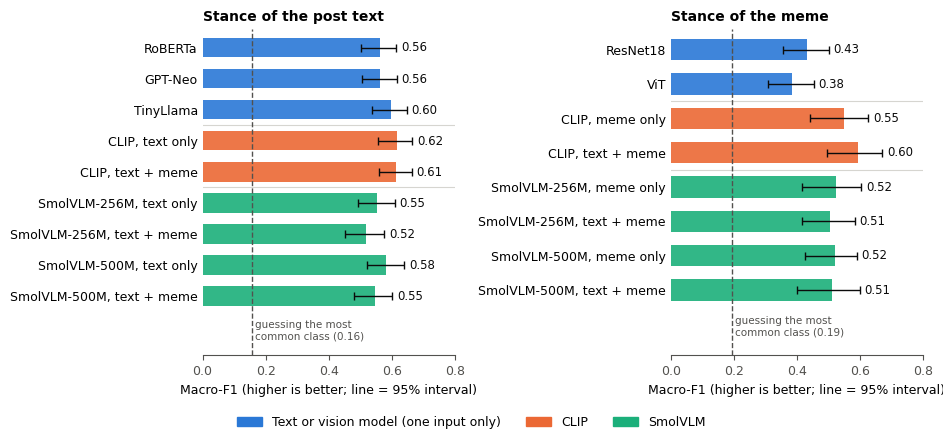

In [15]:
# ================= Figure 1: Showing all models macro-F1 against the majority class in dotted line =================
FIG1_NOTES = {"Post-Text": "",
              "Memes":     ""}

plt.rcParams.update({"font.family": "sans-serif", "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.spines.left": False, "axes.edgecolor": "#52514e",
                     "xtick.color": "#52514e", "savefig.facecolor": "white", "figure.facecolor": "white"})
GROUP_COLORS = {"single": "#2a78d6", "CLIP": "#eb6834", "SmolVLM": "#1baf7a"}
INK, MUTED = "#0b0b0b", "#52514e"
SHOW_NAME = {"RoBERTa-base": "RoBERTa", "GPT-Neo-125M": "GPT-Neo", "TinyLlama-1.1B": "TinyLlama",
             "ResNet18": "ResNet18", "ViT-B/16": "ViT", "CLIP Text": "CLIP, text only", "CLIP Meme": "CLIP, Meme only",
             "CLIP Meme": "CLIP, meme only", "CLIP Text + Meme": "CLIP, text + meme",
             **{f"SmolVLM-{s} {i}": f"SmolVLM-{s}, {i}" for s in SIZES for i in ("text only", "meme only", "text + meme")}}
FIG1 = {"Post-Text": ("Stance of the post text",
                    C1_MODELS[:3] + ["CLIP Text", "CLIP Text + Meme"]
                    + [f"SmolVLM-{s} {i}" for s in SIZES for i in ("text only", "text + meme")]),
        "Memes":   ("Stance of the meme",
                    C2_MODELS[:2] + ["CLIP Meme", "CLIP Text + Meme"]
                    + [f"SmolVLM-{s} {i}" for s in SIZES for i in ("meme only", "text + meme")])}
group_of = lambda n: MODELS[n][0] if MODELS[n][0] in ("CLIP", "SmolVLM") else "single"

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.4))
for ax, (lab, (title, names)) in zip(axes, FIG1.items()):
    T = score_table(lab, names); ys = np.arange(len(T))[::-1]; grp = [group_of(n) for n in names]
    for yv, (_, r), g in zip(ys, T.iterrows(), grp):
        ax.barh(yv, r["Macro-F1"], height=0.62, color=GROUP_COLORS[g], alpha=0.9)
        ax.errorbar(r["Macro-F1"], yv, xerr=[[r["Macro-F1"] - r["CI low"]], [r["CI high"] - r["Macro-F1"]]],
                    color=INK, lw=1, capsize=3)
        ax.text(r["CI high"] + 0.015, yv, f"{r['Macro-F1']:.2f}", va="center", fontsize=8.5, color=INK)
    for i in range(1, len(grp)):
        if grp[i] != grp[i - 1]:
            ax.axhline(ys[i] + 0.5, color="#d6d5d0", lw=0.8)
    maj = SCORES[(lab, "Majority class")][0]
    ax.axvline(maj, color=MUTED, ls="--", lw=1)
    ax.text(maj + 0.01, ys[-1] - 0.75, f"guessing the most\ncommon class ({maj:.2f})", fontsize=7.5, color=MUTED, va="top")
    ax.set_yticks(ys); ax.set_yticklabels([SHOW_NAME[n] for n in names]); ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, 0.8 if T["CI high"].max() < 0.72 else 1.0); ax.set_ylim(-1.9, len(T) - 0.4)
    ax.set_xlabel("Macro-F1 (higher is better; line = 95% interval)")
    ax.set_title(title + ("\n" if FIG1_NOTES[lab] else ""), loc="left", fontweight="bold", fontsize=10)
    if FIG1_NOTES[lab]:
        ax.text(0, 1.0, FIG1_NOTES[lab], transform=ax.transAxes, fontsize=8.5, color=MUTED, va="bottom")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
fig.legend(handles, ["Text or vision model (one input only)", "CLIP", "SmolVLM"], loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
for ext in ("png", "pdf"):
    plt.savefig(OUT / f"figure1_overview.{ext}", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
# ================= Additional Comparison analysis between SmolVLM vs CLIP, details to be saved in supplement =================
SUPP = OUT / "supplement"

# SmolVLM vs CLIP, text + meme comparison
show(diff_table([(lab, f"SmolVLM-{s} text + meme", "CLIP Text + Meme") for lab in ("Post-Text", "Memes") for s in SIZES]),
     "Table S1. SmolVLM vs CLIP, text + meme", "supplement/table_S2_smolvlm_vs_clip.csv")

# Per-class F1 analysis
rows = []
for lab in ("Post-Text", "Memes"):
    names = [n for n in MODELS if (lab, n) in PRED and MODELS[n][0] in ("CLIP", "SmolVLM")]
    for n in names:
        f1 = np.mean([f1_score(Y_CODE[lab], encode(p), labels=list(CODE.values()), average=None, zero_division=0) for p in PRED[(lab, n)]], axis=0)
        rows.append({"Label": lab, "Model": n, **dict(zip(CLASSES, f1))})
S3 = pd.DataFrame(rows)
S3.round(4).to_csv(SUPP / "table_S3_per_class_f1.csv", index=False)
counts = {lab: df[col].value_counts().reindex(CLASSES).fillna(0).astype(int).to_dict() for lab, col in LABEL_COLS.items()}
#print("\n=== Table S3. Per-class F1 (mean over repeats) ===\nposts per class:", counts)
#print(S3.round(2).to_string(index=False))

print("\nAll supplemental tables and figures saved in", OUT)


=== Table S1. SmolVLM vs CLIP, text + meme ===
                 Model A          Model B  Macro-F1 A  Macro-F1 B Difference (A - B) [95% interval]
SmolVLM-256M text + meme CLIP Text + Meme        0.52        0.61              -0.10 [-0.16, -0.03]
SmolVLM-500M text + meme CLIP Text + Meme        0.55        0.61              -0.07 [-0.13, -0.01]
SmolVLM-256M text + meme CLIP Text + Meme        0.51        0.60              -0.09 [-0.18, -0.01]
SmolVLM-500M text + meme CLIP Text + Meme        0.51        0.60              -0.08 [-0.17, -0.00]

All supplemental tables and figures saved in /content/study/results


In [17]:
# ================= Save every prediction with its post ID, then download everything as one zip =================
import shutil

CHECKED = {"Post-Text": "coders' text stance", "Memes": "coders' meme stance"}
ids = df[ID_COL].to_numpy()

# 1. Every prediction: one row per post x system x repeat
rows = []
for (lab, name), P in PRED.items():
    fold_of, count = {}, {}
    for r, tr, te in SPLITS[lab]:                    # which test fold each post was in, per repeat
        count[r] = count.get(r, 0) + 1
        for i in te:
            fold_of[(r, i)] = count[r]
    for r in range(N_REPEATS):
        for i in range(len(df)):
            rows.append({"ID": ids[i], "Checked against": CHECKED[lab], "Model": name,
                         "Repeat": r + 1, "Test fold": fold_of[(r, i)],
                         "Coder stance": Y[lab][i], "Predicted stance": P[r, i],
                         "Correct": P[r, i] == Y[lab][i]})
ALL_PRED = pd.DataFrame(rows)
ALL_PRED.to_csv(OUT / "predictions_all.csv", index=False)

# 2. One row per post: each Model's most frequent prediction over the 5 repeats, and how often it was correct
for lab in LABEL_COLS:
    L = ALL_PRED[ALL_PRED["Checked against"] == CHECKED[lab]]
    most = L.groupby(["ID", "Model"])["Predicted stance"].agg(lambda s: s.value_counts().index[0]).unstack()
    hits = L.groupby(["ID", "Model"])["Correct"].sum().unstack()
    W = pd.DataFrame({"ID": ids, "Coder stance": Y[lab]}).set_index("ID")
    for name in most.columns:
        W[f"{name}: predicted"] = most[name]
        W[f"{name}: times correct (of {N_REPEATS})"] = hits[name].astype(int)
    W.to_csv(OUT / f"predictions_by_post_{'text' if lab == 'Post-Text' else 'meme'}.csv")
print("saved predictions_all.csv,", len(ALL_PRED), "rows")

# 3. Zip the whole results folder and download it
zip_path = shutil.make_archive(str(BASE / "results"), "zip", OUT)
try:
    from google.colab import files
    files.download(zip_path)                         # goes to your browser's download folder
except ImportError:
    print("not in Colab; zip saved at", zip_path)

saved predictions_all.csv, 19000 rows


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>